Dataset shape: (569, 30)
Classes: ['malignant' 'benign']
Class distribution:
0    212
1    357
Name: count, dtype: int64


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6374 - loss: 0.7399 - val_accuracy: 0.5824 - val_loss: 0.6506
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6456 - loss: 0.5734 - val_accuracy: 0.6044 - val_loss: 0.5413
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6731 - loss: 0.4738 - val_accuracy: 0.6703 - val_loss: 0.4730
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7198 - loss: 0.4097 - val_accuracy: 0.7692 - val_loss: 0.4288
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7885 - loss: 0.3718 - val_accuracy: 0.8022 - val_loss: 0.4002
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8516 - loss: 0.3475 - val_accuracy: 0.8791 - val_loss: 0.3783
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8846 - loss: 0.3303 - val_accuracy: 0.8901 - val_loss: 0.3617
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9011 - loss: 0.3166 - val_accuracy: 0.9121 - val_loss:

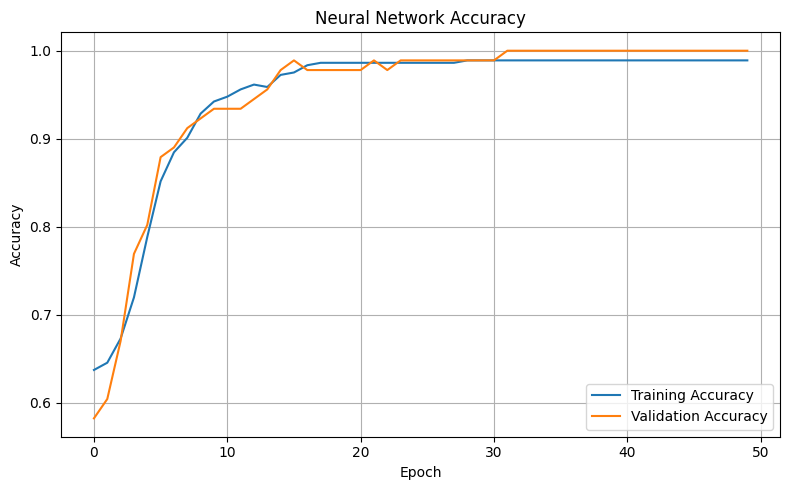

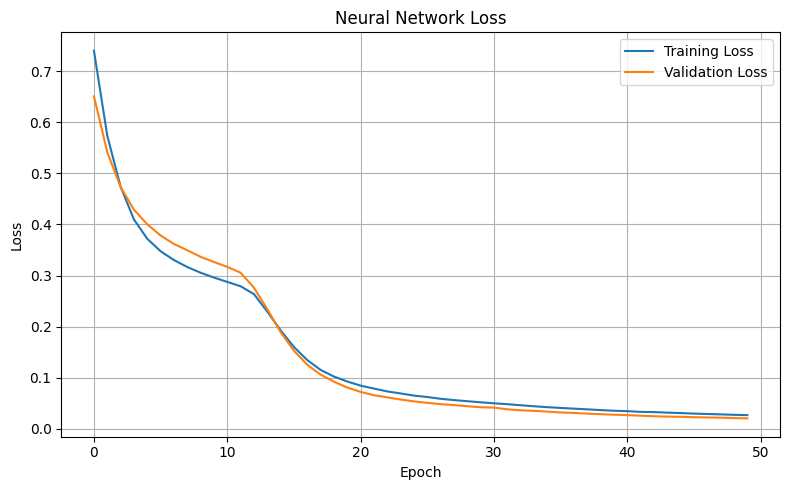


Model Comparison:
                  Model  Test Accuracy
 Random Forest (Task 5)        0.98200
Neural Network (Task 6)        0.95614


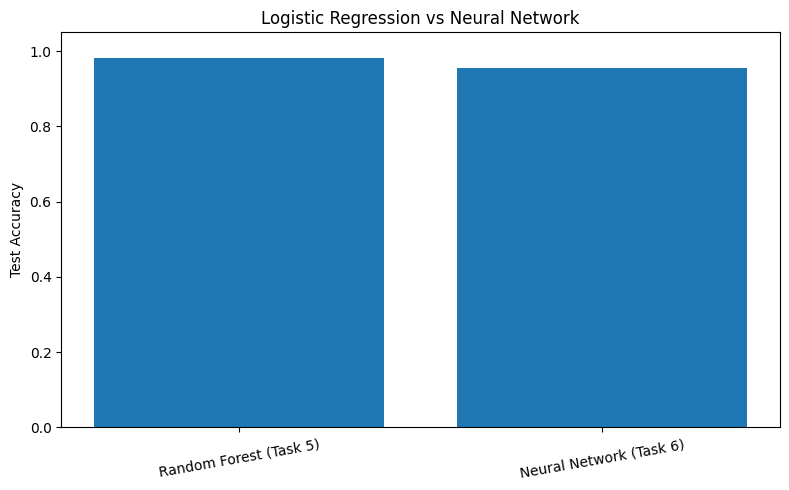

In [4]:
# Part A: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix,classification_report,accuracy_score)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
# Part C: Load dataset
data = load_breast_cancer()
X = data.data
y = data.target
print("Dataset shape:", X.shape)
print("Classes:", data.target_names)
print("Class distribution:")
print(pd.Series(y).value_counts().sort_index())
# Part D: Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)
# Part E: Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
# Part F: Build neural network
model = Sequential([Input(shape=(X_train.shape[1],)),Dense(16, activation="relu"),Dense(8, activation="relu"),Dense(1, activation="sigmoid")])
# Part G: Compile model
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
model.summary()
# Part H: Train model
history = model.fit(X_train,y_train,epochs=50,batch_size=16,validation_split=0.2,verbose=1)
# Part I: Evaluate model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("\nNeural Network Test Results")
print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy, 4))
print("Test Accuracy (%):", round(accuracy * 100, 2))
# Generate predictions
probabilities = model.predict(X_test, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)
# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
# Precision, recall and F1-score
print("\nClassification Report:")
print(classification_report(y_test,y_pred,labels=[0, 1],target_names=["Malignant", "Benign"],zero_division=0))
# Part J: Visualize training performance
# Accuracy plot
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Neural Network Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
# Loss plot
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Neural Network Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
# Part K: Comparison with Task 5 Random Forest
# Task 5 Random Forest test accuracy was 98.2%.
# The neural network accuracy below is calculated from this run.
comparison = pd.DataFrame({"Model": ["Random Forest (Task 5)","Neural Network (Task 6)"],"Test Accuracy": [0.982,accuracy]})
print("\nModel Comparison:")
print(comparison.to_string(index=False))
# Visual comparison
plt.figure(figsize=(8, 5))
plt.bar(comparison["Model"], comparison["Test Accuracy"])
plt.title("Logistic Regression vs Neural Network")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()
